In [8]:
import json
from pathlib import Path

import h5py
import numpy as np
import torch
import torch.nn as nn
from PIL import Image
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader, Subset

from torchvision.transforms import functional as F

In [9]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
print("device: ", device)


def set_seed(seed: int):
    # random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True, warn_only=False)

PyTorch version: 2.14.0+cu126
CUDA available: True
device:  cuda


### Гиперпараметры

In [10]:
SEED = 42
set_seed(SEED)

TRAIN_IMAGES_PATH = Path("SVHN/train")
TRAIN_DIGIT_STRUCT_MAT = Path("SVHN/train_digitStruct.mat")
TRAIN_DIGIT_STRUCT_JSON = Path("SVHN/train_digit_struct.json")

TEST_IMAGES_PATH = Path("SVHN/test")
TEST_DIGIT_STRUCT_MAT = Path("SVHN/test_digitStruct.mat")
TEST_DIGIT_STRUCT_JSON = Path("SVHN/test_digit_struct.json")

# фон (0) + 10 цифр (1-10) = 11 классов
NUM_CLASSES = 11

BATCH_SIZE = 4
VAL_FRACTION = 0.2
EPOCHS = 10
LR = 8e-4

### Обработка датасета
Структура датасета:
- train/ - папка только с изображениями для обучения модели
- test/ - папка только с изображениями для итоговых метрик обученной модели
- train_digitStruct.mat - файл из матлаба с разметкой границ и их классов всех чисел на изображениях для обучения
- test_digitStruct.mat - аналогичен train_digitStruct.mat, но для изображений для теста



In [11]:
def test_mat_file():
    with h5py.File(TRAIN_DIGIT_STRUCT_MAT, "r") as f:
        print("Формат данных в train_digitStruct.mat:")
        digit_struct = f["digitStruct"]
        print(list(digit_struct.keys()))

        name_struct = f["digitStruct"]["name"][0][0]
        name_data = f[name_struct]
        name = "".join(chr(int(i[0])) for i in name_data)
        print(f"Название первого файла: {name}")

        # bbox - bounding box
        bbox_struct = f["digitStruct"]["bbox"][0][0]
        bbox_data = f[bbox_struct]
        bbox = list(i for i in bbox_data)
        print(f"Ключи параметров изображения: {bbox}")


def read_mat_digit_struct(mat_path: Path):
    marks = []
    with h5py.File(mat_path, "r") as f:
        names = f["digitStruct"]["name"]
        bboxes = f["digitStruct"]["bbox"]
        for name_ref, bbox_ref in zip(names, bboxes):
            # получаем имя файла с изображением
            name_data = f[name_ref[0]]
            image_name = "".join(chr(int(value[0])) for value in name_data)

            # получаем структуру с прямоугольниками
            bbox_group = f[bbox_ref[0]]

            # считываем параметры прямоугольников
            fields = {}
            for field in ["left", "top", "width", "height", "label"]:
                data = bbox_group[field]

                if data.shape[0] == 1:
                    # если на изображении только 1 цифра
                    fields[field] = [float(data[0][0])]
                else:
                    # если цифр несколько
                    fields[field] = [float(f[ref][0][0]) for ref in data[:, 0]]

            # формируем словарь с параметрами прямоугольника
            image_boxes = []
            for i in range(len(fields["label"])):
                image_boxes.append({
                    "left": fields["left"][i],
                    "top": fields["top"][i],
                    "width": fields["width"][i],
                    "height": fields["height"][i],
                    "label": int(fields["label"][i])
                })

            # собираем итоговый массив словарей (json)
            marks.append({
                "filename": image_name,
                "boxes": image_boxes
            })

    return marks


def get_digit_struct(json_path: Path, mat_path: Path):
    if json_path.exists():
        with open(json_path, "r", encoding="utf-8") as f:
            train_digit_struct = json.load(f)
    else:
        with open(json_path, "w", encoding="utf-8") as f:
            train_digit_struct = read_mat_digit_struct(mat_path)
            json.dump(train_digit_struct, f)

    return train_digit_struct


test_mat_file()
train_digit_struct = get_digit_struct(TRAIN_DIGIT_STRUCT_JSON, TRAIN_DIGIT_STRUCT_MAT)
print(f"\nДанные для первого изображения:\n{train_digit_struct[0]}")

Формат данных в train_digitStruct.mat
['bbox', 'name']
Название первого файла: 1.png
Ключи параметров изображения: ['height', 'label', 'left', 'top', 'width']

Данные для первого изображения:
{'filename': '1.png', 'boxes': [{'left': 246.0, 'top': 77.0, 'width': 81.0, 'height': 219.0, 'label': 1}, {'left': 323.0, 'top': 81.0, 'width': 96.0, 'height': 219.0, 'label': 9}]}


Главная проблема в файлах из Matlab - для их обработки будем использовать библиотеку h5py. В файлах *_digitStruct.mat данные представлены в своём виде (что-то наподобие ссылок), что затрудняет работу с ними, поэтому с помощью функции read_mat_digit_struct преобразуем эти данные в json-формат. В итоге получаем уже понятный формат для определения положения и классов рамок объектов:

    'filename': '1.png',
    'boxes': [
    {
        'left': 246.0,
        'top': 77.0,
        'width': 81.0,
        'height': 219.0,
        'label': 1
    },
    {
        'left': 323.0,
        'top': 81.0,
        'width': 96.0,
        'height': 219.0,
        'label': 9
    }

In [12]:
class SVHNDataset(Dataset):
    def __init__(self, image_dir, struct_json_path, struct_mat_path):
        self.image_dir = Path(image_dir)
        self.marks = get_digit_struct(struct_json_path, struct_mat_path)

    def __len__(self):
        return len(self.marks)

    def __getitem__(self, idx):
        mark = self.marks[idx]

        image_path = self.image_dir / mark["filename"]
        image = Image.open(image_path).convert("RGB")
        image_width, image_height = image.size

        boxes = []
        labels = []
        for box in mark["boxes"]:
            x1 = box["left"]
            y1 = box["top"]
            x2 = x1 + box["width"]
            y2 = y1 + box["height"]

            # на всякий случай ограничивает bbox, чтобы он не выходил за изображения
            x1 = max(0, min(x1, image_width))
            y1 = max(0, min(y1, image_height))
            x2 = max(0, min(x2, image_width))
            y2 = max(0, min(y2, image_height))

            boxes.append([x1, y1, x2, y2])
            labels.append(box["label"])

        image = F.to_tensor(image)
        boxes = torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4)
        labels = torch.tensor(labels, dtype=torch.int64)
        target = {
            "boxes": boxes,
            "labels": labels
        }

        return image, target

In [ ]:
full_train_dataset = SVHNDataset(TRAIN_IMAGES_PATH, TRAIN_DIGIT_STRUCT_JSON, TRAIN_DIGIT_STRUCT_MAT)

indices = np.arange(len(full_train_dataset))
train_indices, val_indices = train_test_split(
    indices,
    test_size=VAL_FRACTION,
    random_state=SEED,
    shuffle=True
)

train_dataset = Subset(full_train_dataset, train_indices)
val_dataset = Subset(full_train_dataset, val_indices)
test_dataset = SVHNDataset(TEST_IMAGES_PATH, TEST_DIGIT_STRUCT_JSON, TEST_DIGIT_STRUCT_MAT)


def collate_fn(batch):
    return tuple(zip(*batch))


train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn,
    pin_memory=True
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    pin_memory=True
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    pin_memory=True
)

### Создание модели
В качестве модели используется готовая модель fasterrcnn_resnet50_fpn из pytorch.

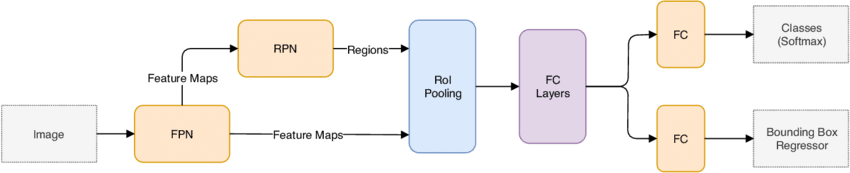
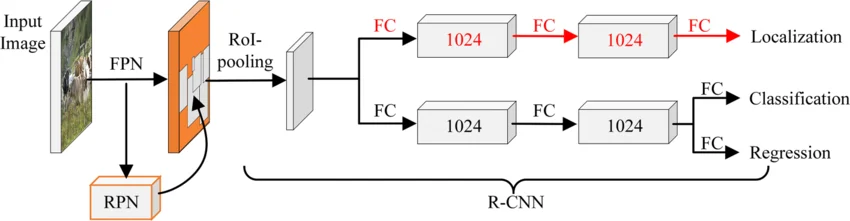

In [ ]:
class ResNet50(nn.Module):
    def __init__(self):
